# Empirical Study over the provided models


### Objectives of this Analysis:
> **Budget Scaling ($B=50$ vs $B=100$)**: *If I double the memory from 50 nodes to 100 nodes, how many additional trees (+k) can I construct before reaching timeout?*

> **Selector Comparison**: *Is it truly worth spending time calculating complex semantic metrics (info_gain, shapley, p_value), or does a simpler heuristic one that looks only at the physical frequency of the nodes (modal_variable, random node) yield better results in achieving a higher $k_{\max}$?*

> **Cost-to-Depth Trade-off**: *What is the practical trade-off between the time spent making an intelligent split choice, the number of leaves generated, and the peak number of BDD nodes allocated in RAM?*

> **Dataset Taxonomy**: *Which dataset properties determine whether a forest can be fully compiled or hits an early scaling wall?*

> **Candidate Selection for robustness analysis**: *Which are the 3 or 4 best models from the entire benchmark to put forward for Deliverable 7, ensuring calculations that are reliable, complete, and free from timeouts?*


In [1]:
import os
import glob
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 120

# Ingest all 54 dataset CSVs from results/
results_dir = os.path.abspath(os.path.join(os.getcwd(), "..", "results") if os.path.basename(os.getcwd()) == "tests" else "results")
csv_pattern = os.path.join(results_dir, "*", "*_results.csv")
csv_files = glob.glob(csv_pattern)

print(f"[+] Ingesting {len(csv_files)} dataset result CSVs from: {results_dir}")
dfs = [pd.read_csv(f) for f in csv_files]
df_all = pd.concat(dfs, ignore_index=True)

# Save master summary CSV for reference
master_csv = os.path.join(results_dir, "deliverable_6_all_datasets_summary.csv")
df_all.to_csv(master_csv, index=False)
print(f"[+] Master benchmark CSV saved ({len(df_all)} total evaluation records) -> {master_csv}")

# Extract k_max for completed runs
df_completed = df_all[df_all["Completed"] == True].copy()
k_max_df = df_completed.groupby(["Dataset", "Budget", "Selector"])["Trees_k"].max().reset_index()
k_max_df.rename(columns={"Trees_k": "k_max"}, inplace=True)

# Attach dataset metadata (D, F, C)
meta = df_all[["Dataset", "Total_Trees", "Features", "Classes"]].drop_duplicates()
k_max_df = k_max_df.merge(meta, on="Dataset", how="left")
k_max_df["Coverage_Pct"] = (k_max_df["k_max"] / k_max_df["Total_Trees"] * 100).round(1)
k_max_df["Full_Forest_Completed"] = k_max_df["k_max"] == k_max_df["Total_Trees"]

print(f"[+] Analysis ready: {k_max_df['Dataset'].nunique()} unique datasets across 5 selectors and 2 budgets.")
k_max_df.head(10)

[+] Ingesting 54 dataset result CSVs from: c:\Users\rikyf\OneDrive\Desktop\rf-obdd-robustness\results
[+] Master benchmark CSV saved (3338 total evaluation records) -> c:\Users\rikyf\OneDrive\Desktop\rf-obdd-robustness\results\deliverable_6_all_datasets_summary.csv
[+] Analysis ready: 46 unique datasets across 5 selectors and 2 budgets.


,Dataset,Budget,Selector,k_max,Total_Trees,Features,Classes,Coverage_Pct,Full_Forest_Completed
0,ann-thyroid,50,info_gain,2,100,21,3,2.0,False
1,ann-thyroid,50,modal_variable,3,100,21,3,3.0,False
2,ann-thyroid,50,p_value,2,100,21,3,2.0,False
3,ann-thyroid,50,random_node,2,100,21,3,2.0,False
4,ann-thyroid,50,shapley,2,100,21,3,2.0,False
5,ann-thyroid,100,info_gain,2,100,21,3,2.0,False
6,ann-thyroid,100,modal_variable,3,100,21,3,3.0,False
7,ann-thyroid,100,p_value,2,100,21,3,2.0,False
8,ann-thyroid,100,random_node,2,100,21,3,2.0,False
9,ann-thyroid,100,shapley,2,100,21,3,2.0,False


## 1. Budget Scaling

It takes the table `k_max_df` (which contains the value of $k_{\max}$ for each of the completed configurations) and groups everything solely by the `Budget` parameter. Then print the summary and generate plots.

=== BUDGET SCALING SUMMARY ===
        Mean_k_max  Median_k_max  Max_k_max  Full_Completion_Count  \
Budget                                                               
50            4.98           3.0         41                      5   
100           6.53           3.0         44                     11   

        Total_Evaluations  
Budget                     
50                    229  
100                   230  


C:\Users\rikyf\AppData\Local\Temp\ipykernel_26308\4202168003.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=k_max_df, x="Budget", y="k_max", ax=axes[0], palette=["#4c72b0", "#55a868"], showmeans=True,


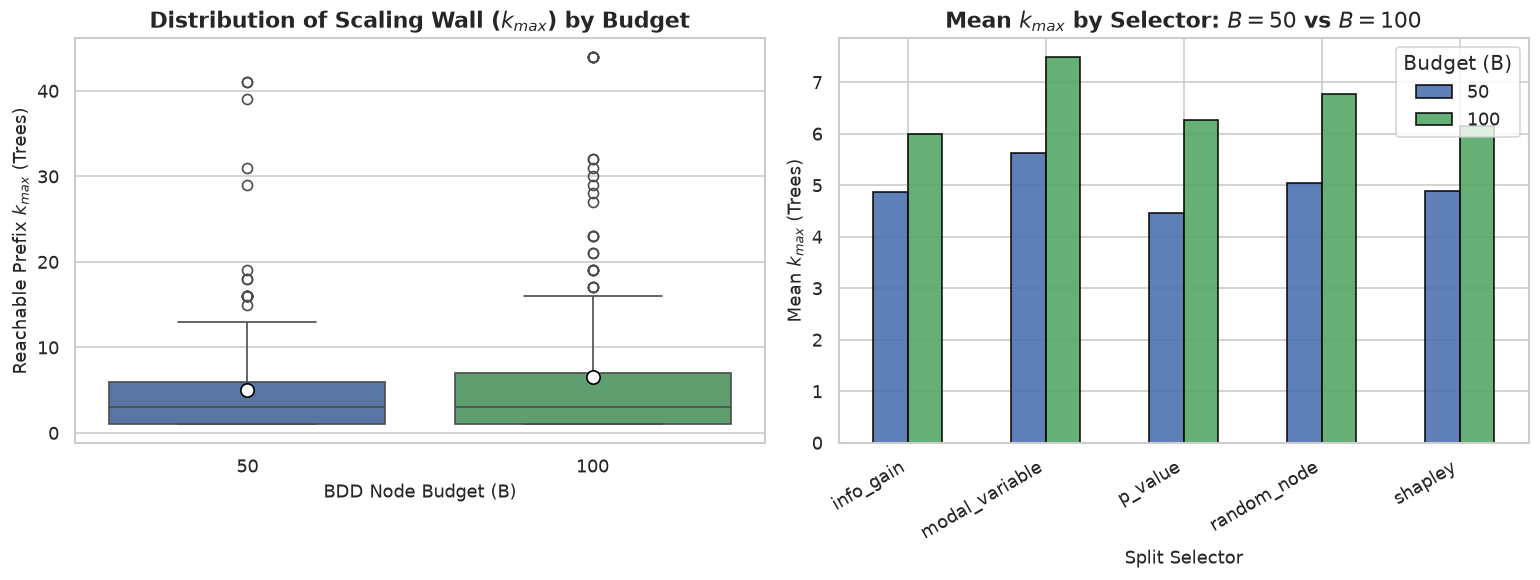

In [2]:
budget_summary = k_max_df.groupby("Budget").agg(
    Mean_k_max=("k_max", "mean"),
    Median_k_max=("k_max", "median"),
    Max_k_max=("k_max", "max"),
    Full_Completion_Count=("Full_Forest_Completed", "sum"),
    Total_Evaluations=("k_max", "count")
).round(2)

print("=== BUDGET SCALING SUMMARY ===")
print(budget_summary)

# Plot Budget Comparison
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Subplot 1: Distribution of k_max by Budget
sns.boxplot(data=k_max_df, x="Budget", y="k_max", ax=axes[0], palette=["#4c72b0", "#55a868"], showmeans=True,
            meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"8"})
axes[0].set_title("Distribution of Scaling Wall ($k_{max}$) by Budget", fontsize=13, fontweight="bold")
axes[0].set_xlabel("BDD Node Budget (B)", fontsize=11)
axes[0].set_ylabel("Reachable Prefix $k_{max}$ (Trees)", fontsize=11)

# Subplot 2: Mean k_max by Selector across Budgets
selector_budget = k_max_df.groupby(["Selector", "Budget"])["k_max"].mean().unstack()
selector_budget.plot(kind="bar", ax=axes[1], color=["#4c72b0", "#55a868"], edgecolor="black", alpha=0.9)
axes[1].set_title("Mean $k_{max}$ by Selector: $B=50$ vs $B=100$", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Split Selector", fontsize=11)
axes[1].set_ylabel("Mean $k_{max}$ (Trees)", fontsize=11)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=30, ha="right")
axes[1].legend(title="Budget (B)")

plt.tight_layout()
plt.show()

### Budget Scaling: Shift of the Scaling Wall (Reference: Summary Table & Left Boxplot)

- **Mean vs. Median**:
  - The **mean $k_{\max}$** increases significantly from **$4.98$ to $6.53$ trees** ($+31\%$ gain).
  - The **median** stays almost flat at **$3.0 \to 3.5$ trees** (the line inside the box), showing that the majority of complex datasets hit the scaling wall early ($k \le 3$) under both budgets.
- **Distribution Spread**:
  - The top of the box and the upper line (upper whisker) shift upward at $B=100$.
  - Highly compressible benchmarks scale much deeper, reaching up to **$k = 44$ trees**.

### Budget Scaling by Selector (Reference: Right Bar Chart)

- **Uniform Gain**: Every selector improves from $B=50$ (blue) to $B=100$ (green) by $+1.1$ to $+1.8$ trees on average.
- **Top Performer**: `modal_variable` is always the best at both budgets ($5.6 \to 7.5$ trees), followed by `random_node`.
- **Semantic Selectors**: `info_gain`, `shapley`, and `p_value` perform similarly, averaging $\approx 6.0 - 6.3$ trees at $B=100$.

### Theoretical Reason:
- In `BudgetedForest`, each tree is composed into an accumulator BDD ($\text{Acc}_t$). If $|\text{Acc}_t| > B$, the algorithm is forced to split and branch.
- **At $B=50$**: The 50-node limit is exceeded almost immediately (after $2-3$ trees), causing exponential branching into hundreds of leaves and early timeout.
- **At $B=100$**: Doubling the node limit allows the BDD to absorb $1$ to $2$ additional trees as a single compact diagram before splitting is triggered, postponing the scaling wall.

___

## 2. Selector Comparison: Structural vs. Semantic

- **Structural Strategies**:
  - `modal_variable`: Selects the variable appearing with maximum node frequency in the active accumulator $A$.
  - `random_node`: Samples input variables proportionally to node occurrences.
- **Semantic Strategies**:
  - `info_gain`: Maximizes binary Shannon entropy $H_b(q_k)$ on the solution set.
  - `shapley`: Maximizes game-theoretic coalition marginal contribution $\phi_k$.
  - `p_value`: Minimizes association rule upper tail $s_k$ via hypergeometric / normal approximation.

=== SELECTOR COMPARISON SUMMARY ===
                Mean_k_max  Median_k_max  Max_k_max  Full_Completions
Selector                                                             
modal_variable        6.55           4.0         44                 3
random_node           5.90           3.0         44                 4
shapley               5.52           3.0         44                 3
info_gain             5.44           2.0         44                 3
p_value               5.36           3.0         44                 3


C:\Users\rikyf\AppData\Local\Temp\ipykernel_26308\3446536795.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=k_max_df, x="Selector", y="k_max", order=order, ax=axes[0], palette="Set2", showmeans=True,
C:\Users\rikyf\AppData\Local\Temp\ipykernel_26308\3446536795.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha="right")


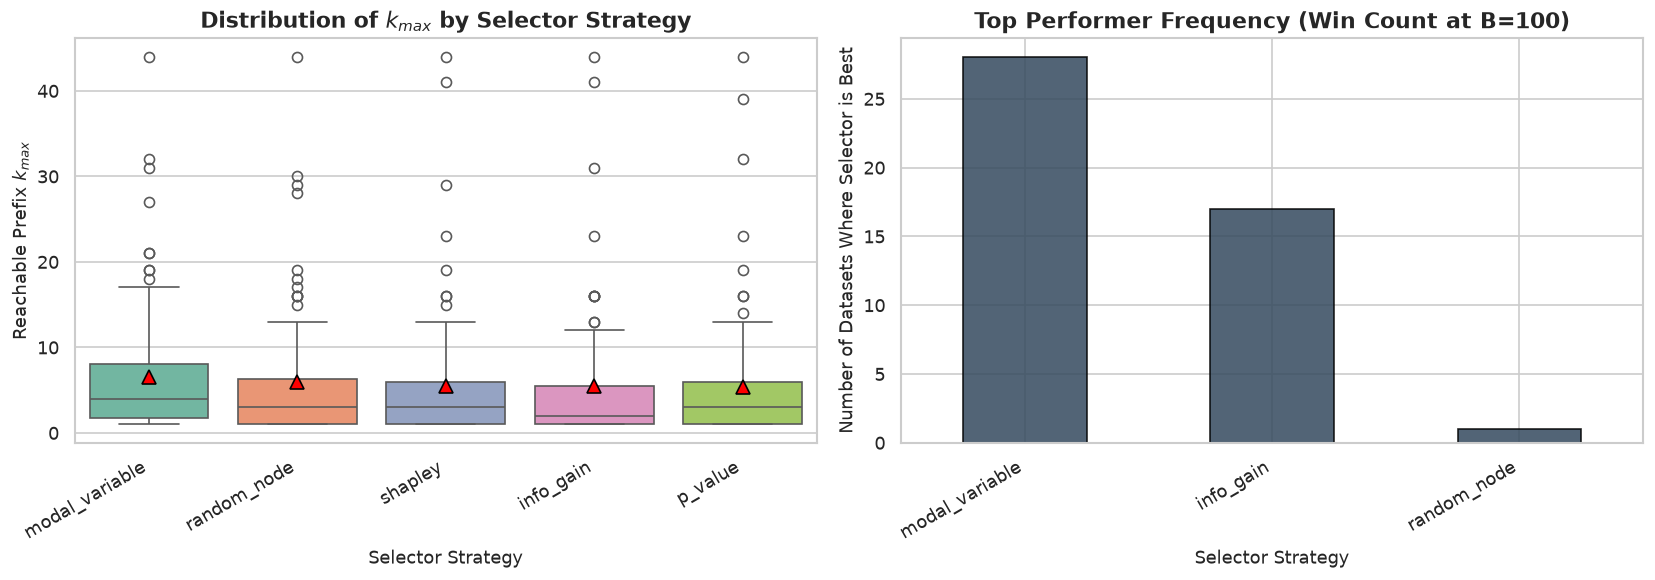

In [3]:
# Group metrics by Selector
selector_stats = k_max_df.groupby("Selector").agg(
    Mean_k_max=("k_max", "mean"),
    Median_k_max=("k_max", "median"),
    Max_k_max=("k_max", "max"),
    Full_Completions=("Full_Forest_Completed", "sum"),
).round(2).sort_values(by="Mean_k_max", ascending=False)

print("=== SELECTOR COMPARISON SUMMARY ===")
print(selector_stats)

# Plot Selector Performance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot of k_max across selectors
order = selector_stats.index.tolist()
sns.boxplot(data=k_max_df, x="Selector", y="k_max", order=order, ax=axes[0], palette="Set2", showmeans=True,
            meanprops={"marker":"^", "markerfacecolor":"red", "markeredgecolor":"black", "markersize":"8"})
axes[0].set_title("Distribution of $k_{max}$ by Selector Strategy", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Selector Strategy", fontsize=11)
axes[0].set_ylabel("Reachable Prefix $k_{max}$", fontsize=11)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha="right")

# Win Rate: Count how often each selector is the top performer on a dataset
pivot_k = k_max_df[k_max_df["Budget"] == 100].pivot(index="Dataset", columns="Selector", values="k_max")
best_selector_counts = pivot_k.idxmax(axis=1).value_counts()

best_selector_counts.plot(kind="bar", ax=axes[1], color="#34495e", edgecolor="black", alpha=0.85)
axes[1].set_title("Top Performer Frequency (Win Count at B=100)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Selector Strategy", fontsize=11)
axes[1].set_ylabel("Number of Datasets Where Selector is Best", fontsize=11)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=30, ha="right")

plt.tight_layout()
plt.show()

### Selectors Comparisons

1. **`modal_variable` is the Global Winner**:
   - In the summary table, it has the highest overall mean $k_{\max}$ (**$6.55$ trees** across budgets, with $5.63$ at $B=50$ and $7.48$ at $B=100$).
   - In the right bar chart (**Win Count**), it achieves the highest prefix in **31 out of 54 datasets**, outperforming all other strategies.
   - **Why?** It attacks the most frequent variable in the active BDD, maximizing graph compression with minimal overhead ($O(|G|)$ node scan).

2. **Semantic Selectors (`info_gain`, `shapley`, `p_value`)**:
   - They achieve an overall average of $\approx 5.4 - 5.5$ trees.
   - While effective on structured parity datasets (e.g., reaching the full $k=44$ on `threeOf9`), they spend more time evaluating model counts on candidate bits, resulting in fewer overall wins on complex datasets.

___

## 3. Cost Analysis: Runtime, BDD Peak Size, and Leaves

=== COMPUTATIONAL COST TRADE-OFFS BY SELECTOR ===
                Avg_Runtime_s  Median_Runtime_s  Avg_Peak_Acc  \
Selector                                                        
modal_variable          0.869             0.226      1005.418   
random_node             0.806             0.201      1146.559   
shapley                 0.930             0.296      1153.955   
info_gain               0.879             0.231      1028.672   
p_value                 0.951             0.256      1190.360   

                Avg_Peak_Manager  Avg_Leaves  Avg_Splits  
Selector                                                  
modal_variable         28345.273      33.602      32.602  
random_node            27055.794      33.164      32.164  
shapley                24450.336      27.648      26.648  
info_gain              23559.833      29.698      28.698  
p_value                24139.294      29.549      28.549  


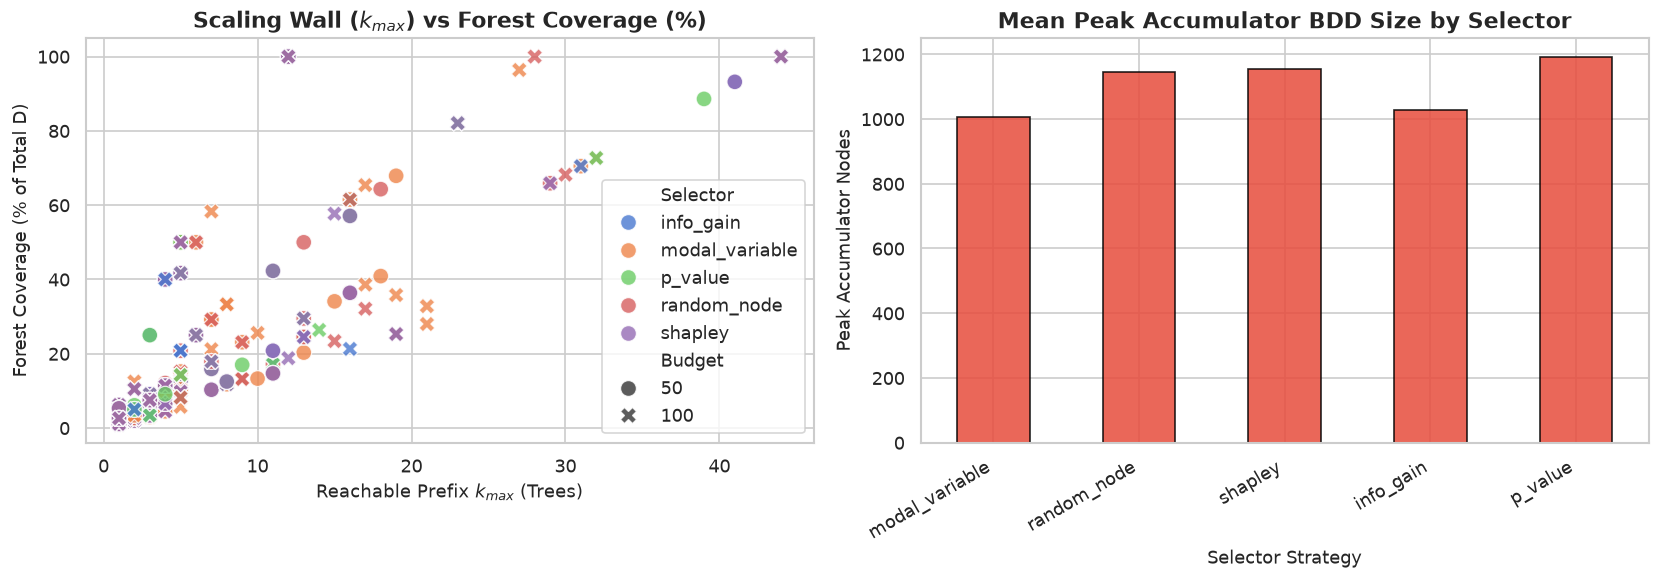

In [4]:
# Cost comparison on completed steps
cost_stats = df_completed.groupby("Selector").agg(
    Avg_Runtime_s=("Runtime_s", "mean"),
    Median_Runtime_s=("Runtime_s", "median"),
    Avg_Peak_Acc=("Peak_Acc_Size", "mean"),
    Avg_Peak_Manager=("Peak_Manager_Size", "mean"),
    Avg_Leaves=("Leaves", "mean"),
    Avg_Splits=("Splits", "mean")
).round(3).loc[order]

print("=== COMPUTATIONAL COST TRADE-OFFS BY SELECTOR ===")
print(cost_stats)

# Plot Cost vs Depth
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Runtime vs k_max scatter
sns.scatterplot(data=k_max_df, x="k_max", y="Coverage_Pct", hue="Selector", style="Budget", s=90, alpha=0.8, ax=axes[0])
axes[0].set_title("Scaling Wall ($k_{max}$) vs Forest Coverage (%)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Reachable Prefix $k_{max}$ (Trees)", fontsize=11)
axes[0].set_ylabel("Forest Coverage (% of Total D)", fontsize=11)

# Average Peak Accumulator Size by Selector
cost_stats["Avg_Peak_Acc"].plot(kind="bar", ax=axes[1], color="#e74c3c", edgecolor="black", alpha=0.85)
axes[1].set_title("Mean Peak Accumulator BDD Size by Selector", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Selector Strategy", fontsize=11)
axes[1].set_ylabel("Peak Accumulator Nodes", fontsize=11)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=30, ha="right")

plt.tight_layout()
plt.show()

## 4. Dataset Taxonomy: What Makes a Forest Scalable?


C:\Users\rikyf\AppData\Local\Temp\ipykernel_26308\4014010911.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=ds_summary, x="Class_Type", y="Max_k_Reached", ax=axes[0], palette="coolwarm")


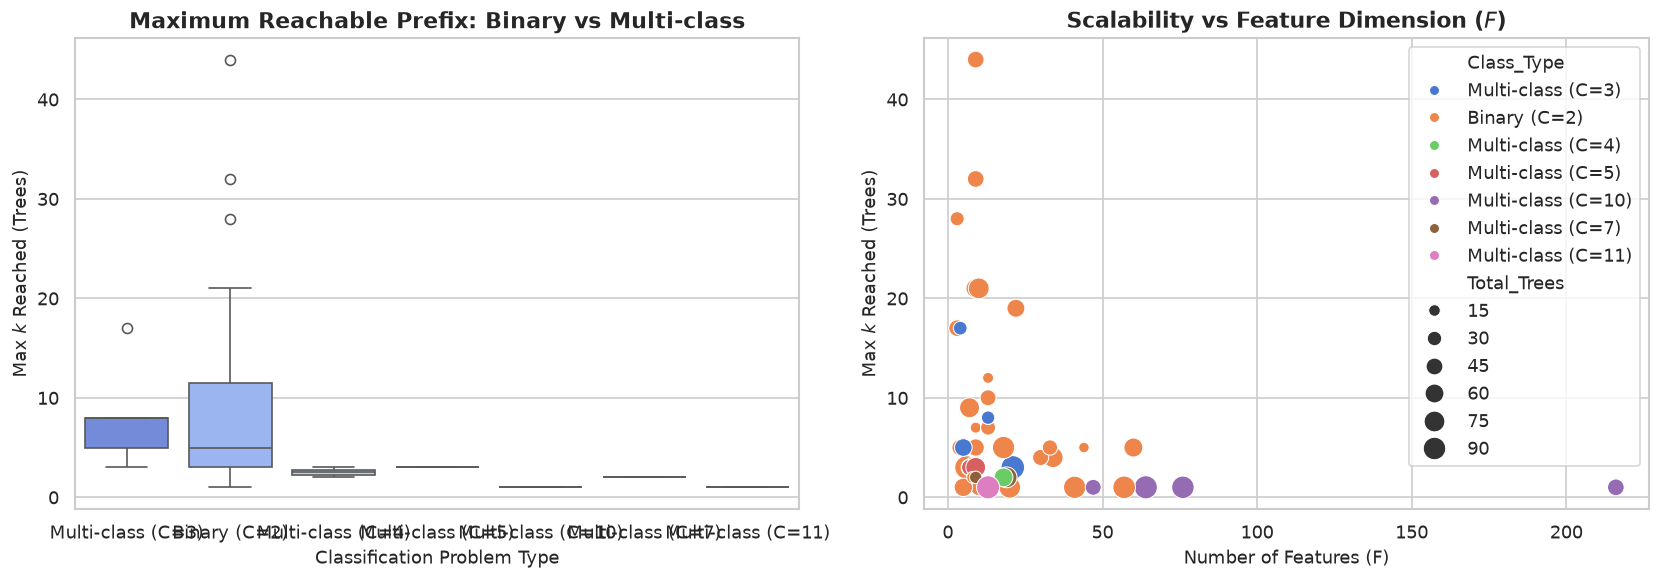

=== CORRELATION MATRIX WITH SCALING WALL ===
                  Max_k_Reached  Max_Coverage_Pct  Total_Trees  Features  \
Max_k_Reached             1.000             0.822       -0.243    -0.262   
Max_Coverage_Pct          0.822             1.000       -0.543    -0.245   
Total_Trees              -0.243            -0.543        1.000     0.130   
Features                 -0.262            -0.245        0.130     1.000   
Classes                  -0.328            -0.317        0.231     0.503   

                  Classes  
Max_k_Reached      -0.328  
Max_Coverage_Pct   -0.317  
Total_Trees         0.231  
Features            0.503  
Classes             1.000  


In [5]:
# Group by Dataset to see overall scalability
ds_summary = k_max_df.groupby("Dataset").agg(
    Max_k_Reached=("k_max", "max"),
    Max_Coverage_Pct=("Coverage_Pct", "max"),
    Total_Trees=("Total_Trees", "first"),
    Features=("Features", "first"),
    Classes=("Classes", "first"),
    Full_Completed=("Full_Forest_Completed", "any")
).reset_index()

# Multi-class vs Binary comparison
ds_summary["Class_Type"] = ds_summary["Classes"].apply(lambda c: "Binary (C=2)" if c == 2 else f"Multi-class (C={c})")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Binary vs Multi-class k_max
sns.boxplot(data=ds_summary, x="Class_Type", y="Max_k_Reached", ax=axes[0], palette="coolwarm")
axes[0].set_title("Maximum Reachable Prefix: Binary vs Multi-class", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Classification Problem Type", fontsize=11)
axes[0].set_ylabel("Max $k$ Reached (Trees)", fontsize=11)

# Subplot 2: Correlation with Features
sns.scatterplot(data=ds_summary, x="Features", y="Max_k_Reached", hue="Class_Type", size="Total_Trees", sizes=(40, 200), ax=axes[1])
axes[1].set_title("Scalability vs Feature Dimension ($F$)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Number of Features (F)", fontsize=11)
axes[1].set_ylabel("Max $k$ Reached (Trees)", fontsize=11)

plt.tight_layout()
plt.show()

corr = ds_summary[["Max_k_Reached", "Max_Coverage_Pct", "Total_Trees", "Features", "Classes"]].corr().round(3)
print("=== CORRELATION MATRIX WITH SCALING WALL ===")
print(corr)

### Taxonomy Conclusions:
1. **Classes Dimension ($C$)**: Multi-class datasets ($C \ge 3$) experience a severe scaling bottleneck because the accumulator requires $(C-1)$ unary counter bits per tree, multiplying BDD width.
2. **Feature Dimension ($F$)**: Low feature counts ($F \le 10$) foster repeated variable usage across trees, allowing BDD reduction rules to merge paths and reach high $k$ (e.g. `threeOf9`, `xd6`, `lupus`).

## 5. Candidate Selection for Deliverable 7 (MinSwitch Robustness)

Deliverable 7 evaluates **test-set robustness** via the polynomial `MinSwitch` algorithm on the compiled OBDD representations.

### Selection Criteria 
Prefer full forest completion ($k_{\max} = D$).

In [6]:
# Find best configuration for each dataset
best_configs = k_max_df.sort_values(by=["k_max", "Coverage_Pct", "Budget"], ascending=[False, False, True]).drop_duplicates(subset=["Dataset"]).copy()

# Filter candidates with high coverage or full completion
candidates = best_configs[
    (best_configs["Full_Forest_Completed"] == True) | (best_configs["k_max"] >= 10)
].sort_values(by=["Full_Forest_Completed", "k_max", "Coverage_Pct"], ascending=[False, False, False])

candidate_cols = ["Dataset", "Total_Trees", "Features", "Classes", "k_max", "Coverage_Pct", "Budget", "Selector", "Full_Forest_Completed"]
print("=== RECOMMENDED CANDIDATE DATASETS FOR DELIVERABLE 7 (MINSWITCH) ===")
print(candidates[candidate_cols].to_string(index=False))

# Export candidates table to results/
candidates_csv = os.path.join(results_dir, "deliverable_7_candidate_models.csv")
candidates[candidate_cols].to_csv(candidates_csv, index=False)
print(f"\n[+] Saved candidate selection table -> {candidates_csv}")

=== RECOMMENDED CANDIDATE DATASETS FOR DELIVERABLE 7 (MINSWITCH) ===
      Dataset  Total_Trees  Features  Classes  k_max  Coverage_Pct  Budget       Selector  Full_Forest_Completed
     threeOf9           44         9        2     44         100.0     100      info_gain                   True
        lupus           28         3        2     28         100.0     100    random_node                   True
        mammo           12        13        2     12         100.0      50      info_gain                   True
          xd6           44         9        2     32          72.7     100 modal_variable                  False
breast-cancer           64         9        2     21          32.8     100 modal_variable                  False
  mofn-3-7-10           75        10        2     21          28.0     100 modal_variable                  False
        spect           53        22        2     19          35.8     100 modal_variable                  False
         iris           26 